<>:139: SyntaxWarning: invalid escape sequence '\O'
<>:148: SyntaxWarning: invalid escape sequence '\O'
<>:139: SyntaxWarning: invalid escape sequence '\O'
<>:148: SyntaxWarning: invalid escape sequence '\O'
C:\Users\ebepo\AppData\Local\Temp\ipykernel_27404\3699810599.py:139: SyntaxWarning: invalid escape sequence '\O'
  ax2.set_ylabel('Weerstand $R$ ($\Omega$)', fontsize=11)
C:\Users\ebepo\AppData\Local\Temp\ipykernel_27404\3699810599.py:148: SyntaxWarning: invalid escape sequence '\O'
  ax3.set_ylabel('$dR/dT$ ($\Omega / \text{K}$)', fontsize=11)


Ijkvergelijking: T[K] = 2.7397 * R_sensor + -5.7397
Aantal ingelezen datapunten: 2116

--- RESULTATEN ---
Buigpunt temperatuur (Max Helling): -313.19 K
Maximale Helling (dR/dT):           nan Ohm/K
Restweerstand Offset:               0.000000 Ohm
Gextrapoleerde Tc:                  nan K


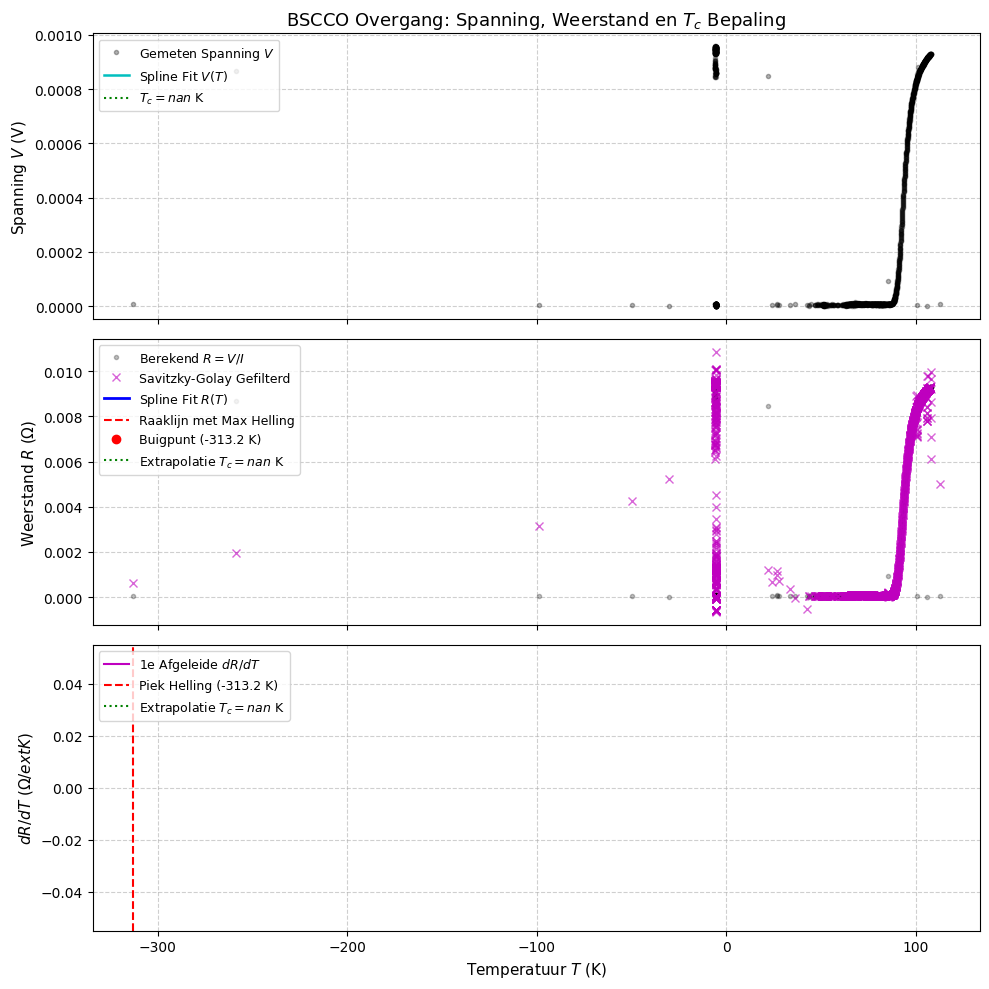

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.interpolate import UnivariateSpline

# ==========================================
# 1. FUNCTIE VOOR HET INLEZEN VAN DE CSV-BESTANDEN
# ==========================================
def load_lab_csv(filepath):
    """
    Leest de laboratorium CSV-bestanden in door de metadata-kopregels 
    automatisch over te slaan en enkel de numerieke meetwaarden te laden.
    """
    with open(filepath, 'r') as f:
        lines = f.readlines()
    
    # Zoek de eerste regel waar de numerieke meetwaarden beginnen
    data_start = 0
    for i, line in enumerate(lines):
        line_str = line.strip()
        if line_str and not '\t' in line_str:
            try:
                float(line_str.split(',')[0])
                data_start = i
                break
            except ValueError:
                pass
                
    values = [float(l.strip()) for l in lines[data_start:] if l.strip()]
    return np.array(values)

# ==========================================
# 2. INSTELLINGEN & BESTANDSPADEN
# ==========================================
# Pas hier de bestandsnamen aan naar de meting die je wilt analyseren:
dmm_file = 'DMMdata_meting1.csv'  # Pt100/Pt1000 thermometer weerstand (Ohm)
smu_file = 'SMUdata_meting1.csv'  # Gemeten spanning over BSCCO sample (Volt)

# Gemeten weerstandswaarden van de temperatuursensor bij de ijkpunten:
R_sensor_77K = 30.2    # Gemeten sensorweerstand bij 77.0 K (vloeibare stikstof)
R_sensor_297K = 110.5  # Gemeten sensorweerstand bij 297.0 K (kamertemperatuur)

# Bronstroom van de Keithley SMU (bijv. 0.1 A = 100 mA)
I_source = 0.1  # Ampere

# ==========================================
# 3. TEMPERATUURIJKING & OHM'S WEG
# ==========================================
# Lineaire ijkvergelijking: T[K] = a * R_sensor + b
a_cal = (297.0 - 77.0) / (R_sensor_297K - R_sensor_77K)
b_cal = 77.0 - a_cal * R_sensor_77K

def sensor_to_kelvin(R_sensor):
    return a_cal * R_sensor + b_cal

# Lees de data rechtstreeks uit de CSV-bestanden
R_sensor_raw = load_lab_csv(dmm_file)
V_raw = load_lab_csv(smu_file)

# Omrekenen naar Temperatuur (K) en BSCCO Weerstand (Ohm)
T_data = sensor_to_kelvin(R_sensor_raw)
R_data = V_raw / I_source

# Sorteer alle datapunten op stijgende temperatuur
sort_order = np.argsort(T_data)
T_data = T_data[sort_order]
V_data = V_raw[sort_order]
R_data = R_data[sort_order]

print(f"Ijkvergelijking: T[K] = {a_cal:.4f} * R_sensor + {b_cal:.4f}")
print(f"Aantal ingelezen datapunten: {len(T_data)}")

# ==========================================
# 4. RUISFILTERING (SAVITZKY-GOLAY) & SPLINE FIT
# ==========================================
# 1. Savitzky-Golay filter om meetruis te onderdrukken
window_len = 15 if len(R_data) >= 15 else (len(R_data) if len(R_data) % 2 != 0 else len(R_data) - 1)
R_smoothed = savgol_filter(R_data, window_length=window_len, polyorder=2)

# 2. UnivariateSpline fit op de gefilterde weerstandsdata
spline = UnivariateSpline(T_data, R_smoothed, s=1e-6)

# Fijn temperatuurnetwerk voor afgeleides en interpolatie
T_fine = np.linspace(T_data.min(), T_data.max(), 5000)
R_fit = spline(T_fine)
V_fit = R_fit * I_source

# Eerste afgeleide dR/dT
dR_dT = spline.derivative(n=1)(T_fine)

# ==========================================
# 5. BUIGPUNT (d2R/dT2 = 0) & Tc EXTRAPOLATIE
# ==========================================
# Vind de temperatuur met de maximale helling (piek van dR/dT)
idx_max_slope = np.argmax(dR_dT)

T_inflection = T_fine[idx_max_slope]
R_inflection = R_fit[idx_max_slope]
m_max = dR_dT[idx_max_slope]

# Bepaal eventuele offset in supergeleidende toestand (lage T)
R_offset = np.mean(R_fit[:50]) if np.mean(R_fit[:50]) > 0 else 0.0

# Bereken Tc als x-snijpunt van de raaklijn op het buigpunt
Tc_extrapolated = T_inflection - ((R_inflection - R_offset) / m_max)

print("\n--- RESULTATEN ---")
print(f"Buigpunt temperatuur (Max Helling): {T_inflection:.2f} K")
print(f"Maximale Helling (dR/dT):           {m_max:.6f} Ohm/K")
print(f"Restweerstand Offset:               {R_offset:.6f} Ohm")
print(f"Gextrapoleerde Tc:                  {Tc_extrapolated:.2f} K")

# ==========================================
# 6. VISUALISATIE
# ==========================================
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

# Raaklijn berekenen voor visualisatie
T_tangent = np.linspace(Tc_extrapolated - 2, T_inflection + 3, 200)
R_tangent = m_max * (T_tangent - T_inflection) + R_inflection

# Grafiek 1: Gemeten Spanning vs Temperatuur
ax1.plot(T_data, V_data, 'k.', alpha=0.3, label='Gemeten Spanning $V$')
ax1.plot(T_fine, V_fit, 'c-', label='Spline Fit $V(T)$', linewidth=1.8)
ax1.axvline(x=Tc_extrapolated, color='g', linestyle=':', label=f'$T_c = {Tc_extrapolated:.1f}$ K')
ax1.set_ylabel('Spanning $V$ (V)', fontsize=11)
ax1.set_title('BSCCO Overgang: Spanning, Weerstand en $T_c$ Bepaling', fontsize=13)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='upper left', fontsize=9)

# Grafiek 2: Weerstand vs Temperatuur met Raaklijn
ax2.plot(T_data, R_data, 'k.', alpha=0.25, label='Berekend $R = V/I$')
ax2.plot(T_data, R_smoothed, 'mx', alpha=0.6, label='Savitzky-Golay Gefilterd')
ax2.plot(T_fine, R_fit, 'b-', label='Spline Fit $R(T)$', linewidth=2)
ax2.plot(T_tangent, R_tangent, 'r--', label='Raaklijn met Max Helling', linewidth=1.5)
ax2.plot(T_inflection, R_inflection, 'ro', label=f'Buigpunt ({T_inflection:.1f} K)')
ax2.axvline(x=Tc_extrapolated, color='g', linestyle=':', label=f'Extrapolatie $T_c = {Tc_extrapolated:.1f}$ K')
ax2.set_ylabel('Weerstand $R$ ($\Omega$)', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(loc='upper left', fontsize=9)

# Grafiek 3: Eerste Afgeleide (dR/dT)
ax3.plot(T_fine, dR_dT, 'm-', label='1e Afgeleide $dR/dT$')
ax3.axvline(x=T_inflection, color='r', linestyle='--', label=f'Piek Helling ({T_inflection:.1f} K)')
ax3.axvline(x=Tc_extrapolated, color='g', linestyle=':', label=f'Extrapolatie $T_c = {Tc_extrapolated:.1f}$ K')
ax3.set_xlabel('Temperatuur $T$ (K)', fontsize=11)
ax3.set_ylabel('$dR/dT$ ($\Omega / \text{K}$)', fontsize=11)
ax3.grid(True, linestyle='--', alpha=0.6)
ax3.legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.show()

<>:146: SyntaxWarning: invalid escape sequence '\O'
<>:153: SyntaxWarning: invalid escape sequence '\O'
<>:146: SyntaxWarning: invalid escape sequence '\O'
<>:153: SyntaxWarning: invalid escape sequence '\O'
C:\Users\ebepo\AppData\Local\Temp\ipykernel_27404\3829090321.py:146: SyntaxWarning: invalid escape sequence '\O'
  ax_r.set_ylabel('Weerstand $R$ (m$\Omega$)', fontsize=11)
C:\Users\ebepo\AppData\Local\Temp\ipykernel_27404\3829090321.py:153: SyntaxWarning: invalid escape sequence '\O'
  ax_dr.set_ylabel('$dR/dT$ (m$\Omega$ / K)', fontsize=11)



          ANALYSIS RESULTATEN ALLE METINGEN            
Measurement  Data points  T_Point of Inflection (K)  Max slope (mOhm/K)  Rest-offset (mOhm)  Extrapolation Tc (K)
    meting1         1576                     112.51           11152.785               0.050                112.51
    meting2          617                     104.22              26.046               0.053                103.84
    meting3          197                      89.09               1.803               0.000                 87.35
  meting_10          235                      90.08               1.709               0.000                 88.32
  meting_11          232                      89.21               2.262               0.000                 87.80
  meting_13          213                      87.91               1.510               0.000                 86.09
   meting_4          357                      87.08               1.482               0.007                 85.21
   meting_5          223       

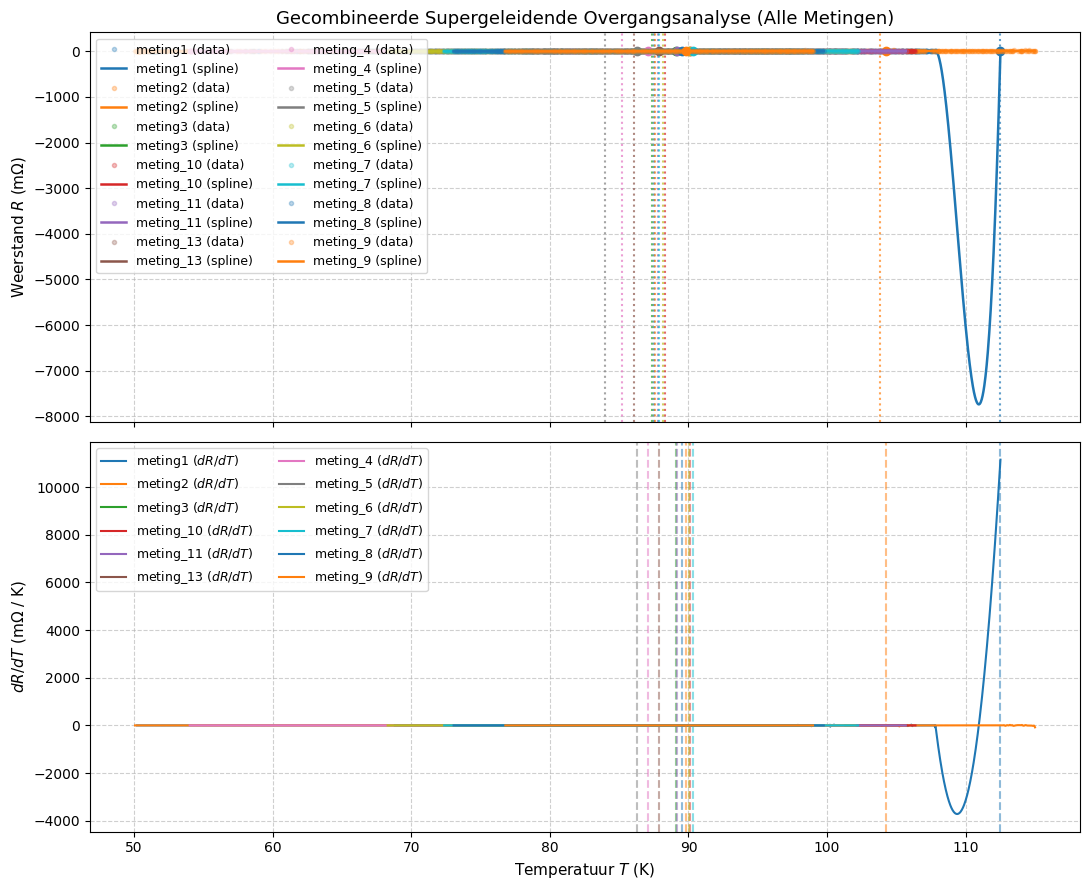

In [10]:
import glob
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.interpolate import UnivariateSpline

# ==========================================
# 1. HELPER FUNCTIE VOOR HET INLEZEN VAN LAB CSV'S
# ==========================================
def load_lab_csv(filepath):
    """
    Leest de laboratorium CSV-bestanden in door de metadata-kopregels 
    automatisch over te slaan en enkel de numerieke meetwaarden te laden.
    """
    with open(filepath, 'r') as f:
        lines = f.readlines()
    
    data_start = 0
    for i, line in enumerate(lines):
        line_str = line.strip()
        if line_str and not '\t' in line_str:
            try:
                float(line_str.split(',')[0])
                data_start = i
                break
            except ValueError:
                pass
                
    values = [float(l.strip()) for l in lines[data_start:] if l.strip()]
    return np.array(values)

# ==========================================
# 2. IJKING & PARAMETERS
# ==========================================
# IJking temperatuursensor (Pt100/Pt1000)
R_sensor_77K = 30.2    # Gemeten weerstand bij 77 K (vloeibare stikstof)
R_sensor_297K = 110.5  # Gemeten weerstand bij 297 K (kamertemperatuur)

a_cal = (297.0 - 77.0) / (R_sensor_297K - R_sensor_77K)
b_cal = 77.0 - a_cal * R_sensor_77K

def sensor_to_kelvin(R_sensor):
    return a_cal * R_sensor + b_cal

# Bronstroom SMU (100 mA)
I_source = 0.1

# ==========================================
# 3. AUTOMATISCHE VERWERKING VAN ALLE METINGEN
# ==========================================
smu_files = sorted(glob.glob('SMUdata*.csv'))
dmm_files = sorted(glob.glob('DMMdata*.csv'))

results = []
summary_data = []

# Maak figuren aan voor vergelijkende visualisatie
fig, (ax_r, ax_dr) = plt.subplots(2, 1, figsize=(11, 9), sharex=True)

for smu_path, dmm_path in zip(smu_files, dmm_files):
    meas_name = os.path.basename(smu_path).replace('SMUdata_', '').replace('.csv', '')
    
    # Inlezen
    V_raw = load_lab_csv(smu_path)
    R_sensor_raw = load_lab_csv(dmm_path)
    
    # Check of lengtes overeenkomen
    if len(V_raw) != len(R_sensor_raw) or len(V_raw) < 20:
        print(f"Sla {meas_name} over wegens afwijkende dataomvang.")
        continue
        
    # Omrekenen
    T_raw = sensor_to_kelvin(R_sensor_raw)
    R_raw = V_raw / I_source
    
    # Filteren van geldige overgangstemperaturen (50 K - 115 K) en opschonen van ruis
    mask = (T_raw >= 50) & (T_raw <= 115) & (R_raw >= -0.005) & (R_raw <= 0.05)
    T_clean = T_raw[mask]
    R_clean = R_raw[mask]
    
    if len(T_clean) < 15:
        continue
        
    # Sorteren op temperatuur
    sort_idx = np.argsort(T_clean)
    T_clean = T_clean[sort_idx]
    R_clean = R_clean[sort_idx]
    
    # Savitzky-Golay ruisfilter
    window_len = 15 if len(R_clean) >= 15 else (len(R_clean) if len(R_clean) % 2 != 0 else len(R_clean) - 1)
    R_smooth = savgol_filter(R_clean, window_length=window_len, polyorder=2)
    
    # Spline fit
    try:
        spline = UnivariateSpline(T_clean, R_smooth, s=1e-6)
        T_fine = np.linspace(T_clean.min(), T_clean.max(), 3000)
        R_fit = spline(T_fine)
        dR_dT = spline.derivative(n=1)(T_fine)
        
        # Bepaling Buigpunt (piek 1e afgeleide)
        idx_max = np.argmax(dR_dT)
        T_inflection = T_fine[idx_max]
        R_inflection = R_fit[idx_max]
        m_max = dR_dT[idx_max]
        
        # Offset & Extrapolatie Tc
        R_offset = np.mean(R_fit[:50]) if np.mean(R_fit[:50]) > 0 else 0.0
        Tc_extrapolated = T_inflection - ((R_inflection - R_offset) / m_max)
        
        # Resultaten opslaan
        summary_data.append({
            'Measurement': meas_name,
            'Data points': len(T_clean),
            'T_Point of Inflection (K)': round(T_inflection, 2),
            'Max slope (mOhm/K)': round(m_max * 1000, 3),
            'Rest-offset (mOhm)': round(R_offset * 1000, 3),
            'Extrapolation Tc (K)': round(Tc_extrapolated, 2)
        })
        
        # Plotten in gecombineerde grafiek
        line, = ax_r.plot(T_clean, R_clean * 1000, '.', alpha=0.3, label=f'{meas_name} (data)')
        color = line.get_color()
        ax_r.plot(T_fine, R_fit * 1000, '-', color=color, linewidth=1.8, label=f'{meas_name} (spline)')
        ax_r.plot(T_inflection, R_inflection * 1000, 'o', color=color, markersize=6)
        ax_r.axvline(x=Tc_extrapolated, color=color, linestyle=':', alpha=0.7)
        
        ax_dr.plot(T_fine, dR_dT * 1000, '-', color=color, label=f'{meas_name} ($dR/dT$)')
        ax_dr.axvline(x=T_inflection, color=color, linestyle='--', alpha=0.5)
        
    except Exception as e:
        print(f"Fout bij verwerken van {meas_name}: {e}")

# ==========================================
# 4. TABEL & VISUALISATIE OPMAAK
# ==========================================
df_summary = pd.DataFrame(summary_data)

print("\n=======================================================")
print("          ANALYSIS RESULTATEN ALLE METINGEN            ")
print("=======================================================")
print(df_summary.to_string(index=False))

# Opmaak Grafiek 1: Weerstand vs Temperatuur
ax_r.set_ylabel('Weerstand $R$ (m$\Omega$)', fontsize=11)
ax_r.set_title('Gecombineerde Supergeleidende Overgangsanalyse (Alle Metingen)', fontsize=13)
ax_r.grid(True, linestyle='--', alpha=0.6)
ax_r.legend(loc='upper left', fontsize=9, ncol=2)

# Opmaak Grafiek 2: Eerste Afgeleide dR/dT
ax_dr.set_xlabel('Temperatuur $T$ (K)', fontsize=11)
ax_dr.set_ylabel('$dR/dT$ (m$\Omega$ / K)', fontsize=11)
ax_dr.grid(True, linestyle='--', alpha=0.6)
ax_dr.legend(loc='upper left', fontsize=9, ncol=2)

plt.tight_layout()
plt.show()

<>:131: SyntaxWarning: invalid escape sequence '\ '
<>:131: SyntaxWarning: invalid escape sequence '\O'
<>:140: SyntaxWarning: invalid escape sequence '\O'
<>:141: SyntaxWarning: invalid escape sequence '\O'
<>:142: SyntaxWarning: invalid escape sequence '\ '
<>:142: SyntaxWarning: invalid escape sequence '\O'
<>:131: SyntaxWarning: invalid escape sequence '\ '
<>:131: SyntaxWarning: invalid escape sequence '\O'
<>:140: SyntaxWarning: invalid escape sequence '\O'
<>:141: SyntaxWarning: invalid escape sequence '\O'
<>:142: SyntaxWarning: invalid escape sequence '\ '
<>:142: SyntaxWarning: invalid escape sequence '\O'
C:\Users\ebepo\AppData\Local\Temp\ipykernel_27404\4182975685.py:131: SyntaxWarning: invalid escape sequence '\ '
  l2, = ax1.plot(T_tangent, R_tangent * 1000, 'r--', linewidth=1.6, label=f'Tangent line ($m={m_max*1000:.2f}\ \mathrm{{m\Omega/K}}$)')
C:\Users\ebepo\AppData\Local\Temp\ipykernel_27404\4182975685.py:131: SyntaxWarning: invalid escape sequence '\O'
  l2, = ax1.pl

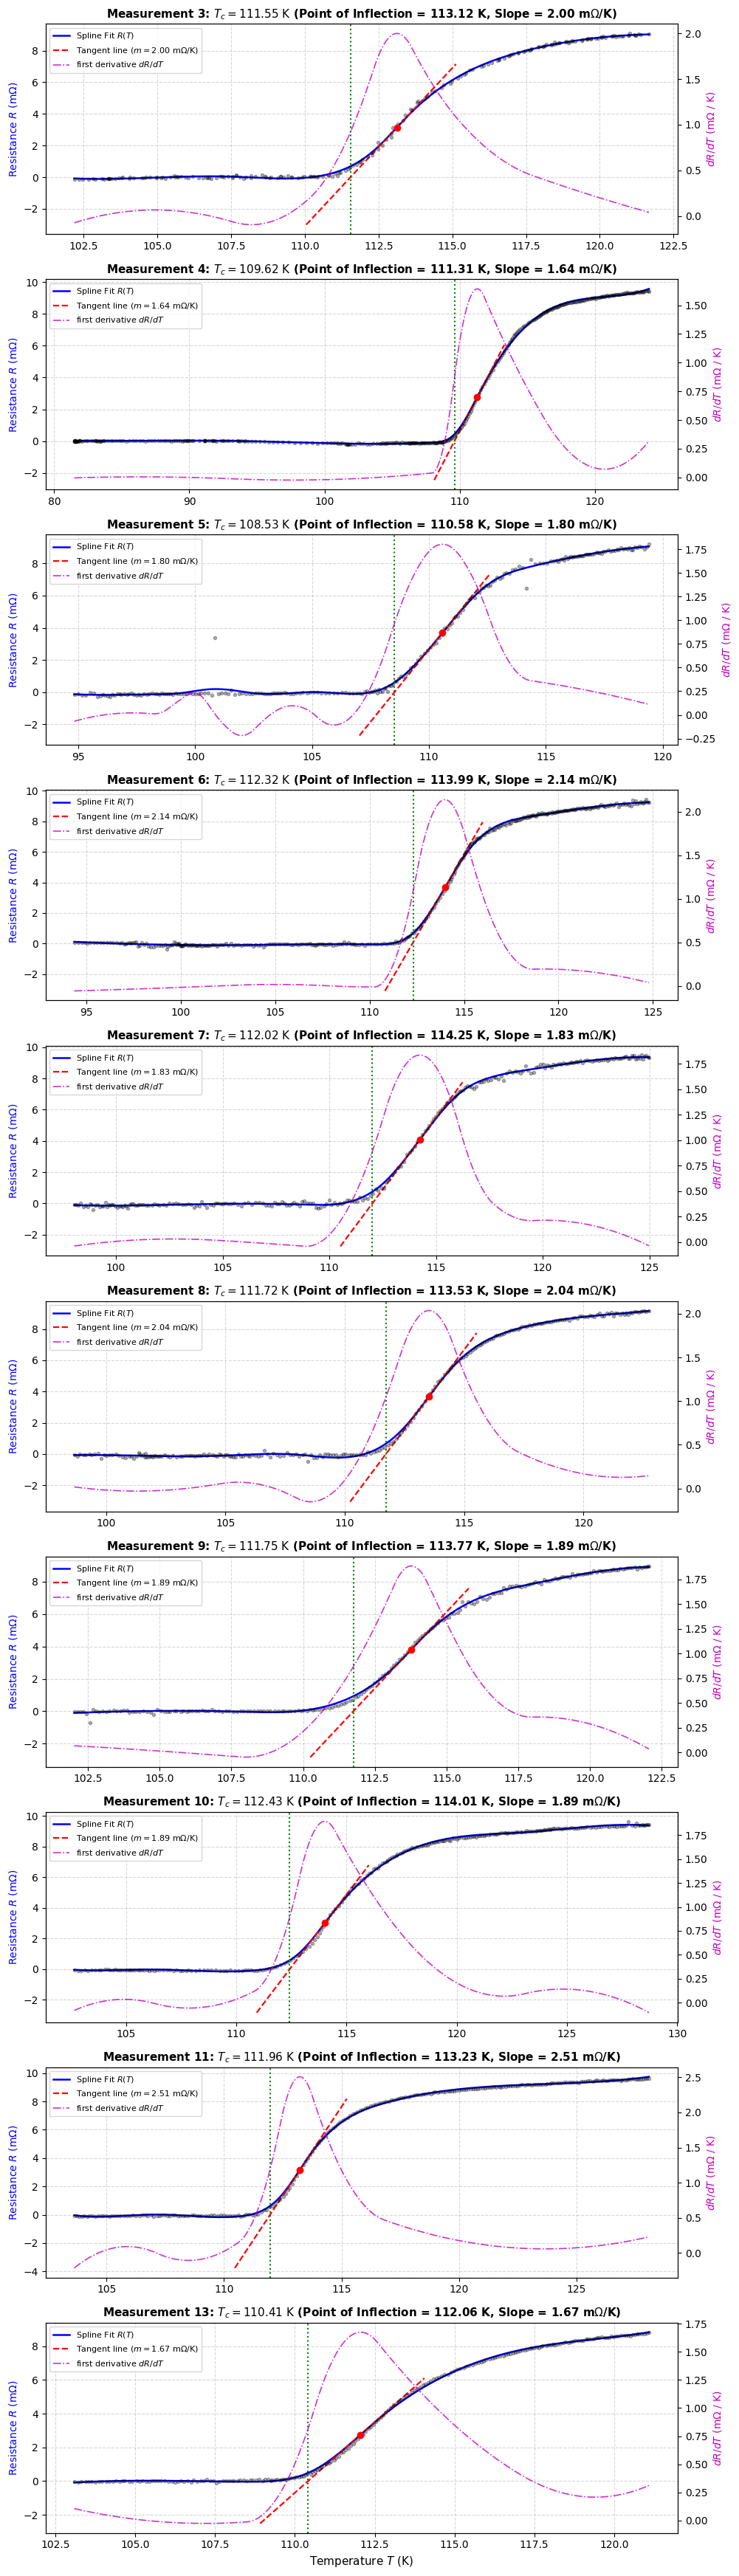


          ANALYSIS RESULTATEN ALLE METINGEN            
   Measurement  Point of inflection (K)  Max Slope (mOhm/K)  Extrapolation Tc (K)
 Measurement 3                   113.12               1.999                111.55
 Measurement 4                   111.31               1.643                109.62
 Measurement 5                   110.58               1.802                108.53
 Measurement 6                   113.99               2.139                112.32
 Measurement 7                   114.25               1.834                112.02
 Measurement 8                   113.53               2.036                111.72
 Measurement 9                   113.77               1.886                111.75
Measurement 10                   114.01               1.894                112.43
Measurement 11                   113.23               2.507                111.96
Measurement 13                   112.06               1.674                110.41


In [9]:
import glob
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.interpolate import UnivariateSpline

# ==========================================
# 1. HELPER FUNCTIE VOOR INLEZEN CSV-BESTANDEN
# ==========================================
def load_lab_csv(filepath):
    """
    Leest de laboratorium CSV-bestanden in door metadata-kopregels 
    over te slaan en enkel de numerieke meetwaarden te laden.
    """
    with open(filepath, 'r') as f:
        lines = f.readlines()
    
    data_start = 0
    for i, line in enumerate(lines):
        line_str = line.strip()
        if line_str and not '\t' in line_str:
            try:
                float(line_str.split(',')[0])
                data_start = i
                break
            except ValueError:
                pass
                
    values = [float(l.strip()) for l in lines[data_start:] if l.strip()]
    return np.array(values)

# ==========================================
# 2. OORSPRONKELIJKE IJKPARAMETERS
# ==========================================
R_sensor_77K = 20    # Pt sensor weerstand bij 77 K (Ohm)[cite: 16]
R_sensor_297K = 109  # Pt sensor weerstand bij 297 K (Ohm)[cite: 16]

a_cal = (297.0 - 77.0) / (R_sensor_297K - R_sensor_77K)
b_cal = 77.0 - a_cal * R_sensor_77K

def sensor_to_kelvin(R_sensor):
    return a_cal * R_sensor + b_cal

I_source = 0.1  # Keithley SMU bronstroom (100 mA)[cite: 16, 19]

# ==========================================
# 3. METINGEN KOPPELEN (EXCLUSIEF METING 1 EN 2)
# ==========================================
smu_files = sorted(glob.glob('SMUdata*.csv'))
dmm_files = sorted(glob.glob('DMMdata*.csv'))

pairs = []
for smu in smu_files:
    meas_id = smu.replace('SMUdata_meting', '').replace('SMUdata_meting_', '').replace('.csv', '')
    if meas_id in ['1', '2']:  # Sluit mislukte metingen 1 en 2 uit
        continue
        
    dmm_candidates = [d for d in dmm_files if f"meting_{meas_id}.csv" in d or f"meting{meas_id}.csv" in d or f"meting_{meas_id}_2.csv" in d]
    if dmm_candidates:
        pairs.append((meas_id, smu, dmm_candidates[0]))

# Sorteer op numerieke volgorde (3, 4, 5, 6, 7, 8, 9, 10)
pairs = sorted(pairs, key=lambda x: int(x[0].replace('_', '')))

# ==========================================
# 4. GRAFIEKEN MET RAAKLIJN GENEREREN
# ==========================================
num_plots = len(pairs)
fig, axes = plt.subplots(num_plots, 1, figsize=(10, 3.5 * num_plots), sharex=False)

summary_data = []

for i, (meas_id, smu_path, dmm_path) in enumerate(pairs):
    clean_label = f"Measurement {meas_id.replace('_', '')}"
    
    # Inlezen
    V_raw = load_lab_csv(smu_path)
    R_sensor_raw = load_lab_csv(dmm_path)
    
    # Omrekenen met oorspronkelijke ijking
    T_raw = sensor_to_kelvin(R_sensor_raw)
    R_raw = V_raw / I_source
    
    # Filteren & Sorteren
    mask = (T_raw >= 40) & (T_raw <= 150) & (R_raw >= -0.005) & (R_raw <= 0.05)
    T_clean = T_raw[mask]
    R_clean = R_raw[mask]
    
    sort_idx = np.argsort(T_clean)
    T_clean = T_clean[sort_idx]
    R_clean = R_clean[sort_idx]
    
    # Savitzky-Golay ruisfilter
    window_len = 15 if len(R_clean) >= 15 else (len(R_clean) if len(R_clean) % 2 != 0 else len(R_clean) - 1)
    R_smooth = savgol_filter(R_clean, window_length=window_len, polyorder=2)
    
    # Spline Fit
    spline = UnivariateSpline(T_clean, R_smooth, s=1e-6)
    T_fine = np.linspace(T_clean.min(), T_clean.max(), 3000)
    R_fit = spline(T_fine)
    dR_dT = spline.derivative(n=1)(T_fine)
    
    # Buigpunt & Max Helling
    idx_max = np.argmax(dR_dT)
    T_inflection = T_fine[idx_max]
    R_inflection = R_fit[idx_max]
    m_max = dR_dT[idx_max]
    
    # Rest-offset & Extrapolatie Tc
    R_offset = np.mean(R_fit[:30]) if np.mean(R_fit[:30]) > 0 else 0.0
    Tc_extrapolated = T_inflection - ((R_inflection - R_offset) / m_max)
    
    summary_data.append({
        'Measurement': clean_label,
        'Point of inflection (K)': round(T_inflection, 2),
        'Max Slope (mOhm/K)': round(m_max * 1000, 3),
        'Extrapolation Tc (K)': round(Tc_extrapolated, 2)
    })
    
    ax1 = axes[i]
    ax2 = ax1.twinx()  # Rechter as voor dR/dT
    
    # Raaklijn berekenen rond het buigpunt tot R = 0
    T_tangent = np.linspace(Tc_extrapolated - 1.5, T_inflection + 2.0, 200)
    R_tangent = m_max * (T_tangent - T_inflection) + R_inflection
    
    # Linker as: Weerstand R(T), Spline Fit & Raaklijn
    l1, = ax1.plot(T_fine, R_fit * 1000, 'b-', linewidth=1.8, label='Spline Fit $R(T)$')
    l2, = ax1.plot(T_tangent, R_tangent * 1000, 'r--', linewidth=1.6, label=f'Tangent line ($m={m_max*1000:.2f}\ \mathrm{{m\Omega/K}}$)')
    ax1.plot(T_clean, R_clean * 1000, 'k.', alpha=0.3, label='Gemeten data')
    ax1.plot(T_inflection, R_inflection * 1000, 'ro', markersize=6)
    ax1.axvline(x=Tc_extrapolated, color='g', linestyle=':', linewidth=1.5, label=f'$T_c = {Tc_extrapolated:.2f}$ K')
    
    # Rechter as: Eerste afgeleide dR/dT
    l3, = ax2.plot(T_fine, dR_dT * 1000, 'm-.', linewidth=1.2, alpha=0.8, label='first derivative $dR/dT$')
    
    # Opmaak assen & labels
    ax1.set_ylabel('Resistance $R$ (m$\Omega$)', color='b', fontsize=10)
    ax2.set_ylabel('$dR/dT$ (m$\Omega$ / K)', color='m', fontsize=10)
    ax1.set_title(f"{clean_label}: $T_c = {Tc_extrapolated:.2f}\ \mathrm{{K}}$ (Point of Inflection = {T_inflection:.2f} K, Slope = {m_max*1000:.2f} m$\Omega$/K)", fontsize=11, fontweight='bold')
    ax1.grid(True, linestyle='--', alpha=0.5)
    
    # Gecombineerde legende per plot
    lines = [l1, l2, l3]
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='upper left', fontsize=8)

axes[-1].set_xlabel('Temperature $T$ (K)', fontsize=11)
plt.tight_layout()
plt.show()

# Print overzichtstabel
df_summary = pd.DataFrame(summary_data)
print("\n=======================================================")
print("          ANALYSIS RESULTATEN ALLE METINGEN            ")
print("=======================================================")
print(df_summary.to_string(index=False))

<>:22: SyntaxWarning: invalid escape sequence '\c'
<>:26: SyntaxWarning: invalid escape sequence '\O'
<>:22: SyntaxWarning: invalid escape sequence '\c'
<>:26: SyntaxWarning: invalid escape sequence '\O'
C:\Users\ebepo\AppData\Local\Temp\ipykernel_24224\1252901946.py:22: SyntaxWarning: invalid escape sequence '\c'
  label=f'Calibration Fit: $T = {a:.4f} \cdot R + {b:.2f}$',
C:\Users\ebepo\AppData\Local\Temp\ipykernel_24224\1252901946.py:26: SyntaxWarning: invalid escape sequence '\O'
  plt.xlabel('Pt1000 Resistance $R$ ($\Omega$)', fontsize=11)


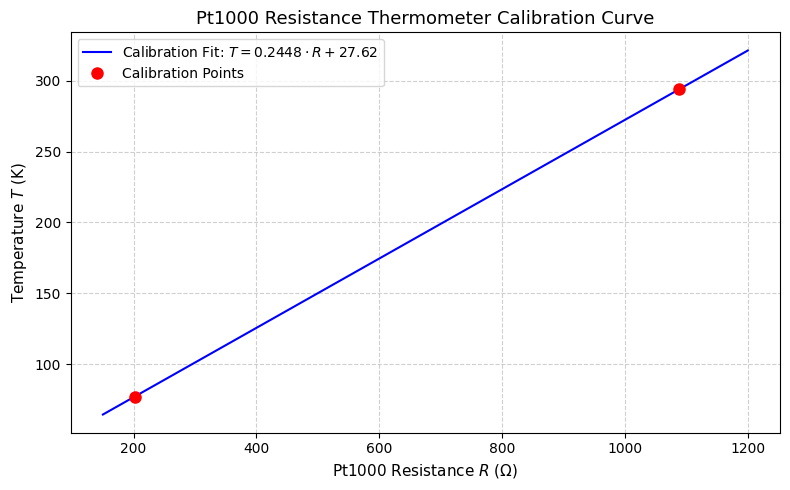

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# Calibration points
R_cal = np.array([201.7, 1088.0])
T_cal = np.array([77.0, 294.0])

# Linear slope (a) and intercept (b)
a = (294.0 - 77.0) / (1088.0 - 201.7)
b = 77.0 - a * 201.7

# Evaluation line range
R_range = np.linspace(150, 1200, 200)
T_range = a * R_range + b

# Plotting
plt.figure(figsize=(8, 5))
plt.plot(
    R_range,
    T_range,
    'b-',
    label=f'Calibration Fit: $T = {a:.4f} \cdot R + {b:.2f}$',
)
plt.plot(R_cal, T_cal, 'ro', markersize=8, label='Calibration Points')

plt.xlabel('Pt1000 Resistance $R$ ($\Omega$)', fontsize=11)
plt.ylabel('Temperature $T$ (K)', fontsize=11)
plt.title('Pt1000 Resistance Thermometer Calibration Curve', fontsize=13)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10)

plt.tight_layout()
plt.show()

<>:22: SyntaxWarning: invalid escape sequence '\c'
<>:26: SyntaxWarning: invalid escape sequence '\O'
<>:22: SyntaxWarning: invalid escape sequence '\c'
<>:26: SyntaxWarning: invalid escape sequence '\O'
C:\Users\ebepo\AppData\Local\Temp\ipykernel_24224\1768466298.py:22: SyntaxWarning: invalid escape sequence '\c'
  label=f'Calibration Fit: $T = {a:.4f} \cdot R + {b:.2f}$',
C:\Users\ebepo\AppData\Local\Temp\ipykernel_24224\1768466298.py:26: SyntaxWarning: invalid escape sequence '\O'
  plt.xlabel('Pt100 Resistance $R$ ($\Omega$)', fontsize=11)


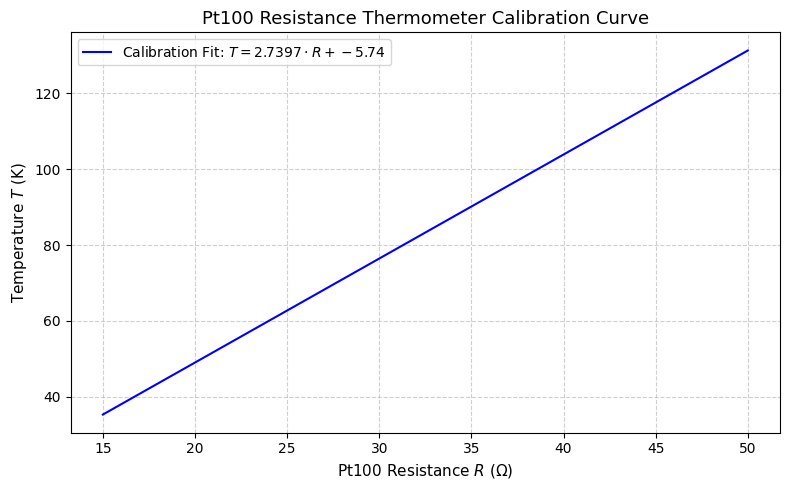

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Calibration points
R_cal = np.array([30.2, 110.5])
T_cal = np.array([77.0, 297.0])

# Linear slope (a) and intercept (b)
a = (297.0 - 77.0) / (110.5 - 30.2)
b = 77.0 - a * 30.2

# Evaluation line range
R_range = np.linspace(15, 50, 200)
T_range = a * R_range + b

# Plotting
plt.figure(figsize=(8, 5))
plt.plot(
    R_range,
    T_range,
    'b-',
    label=f'Calibration Fit: $T = {a:.4f} \cdot R + {b:.2f}$',
)
#plt.plot(R_cal, T_cal, 'ro', markersize=8, label='Calibration Points')

plt.xlabel('Pt100 Resistance $R$ ($\Omega$)', fontsize=11)
plt.ylabel('Temperature $T$ (K)', fontsize=11)
plt.title('Pt100 Resistance Thermometer Calibration Curve', fontsize=13)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10)

plt.tight_layout()
plt.show()